In [28]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import time
import src
import importlib
# allow reloading 
importlib.reload(src)

<module 'src' from 'c:\\Users\\jiyue\\OneDrive - UC San Diego\\python_projects\\corr\\src.py'>

## Random field simulation 

First, we simulate two correlated 2D random feilds and visualiza them. 

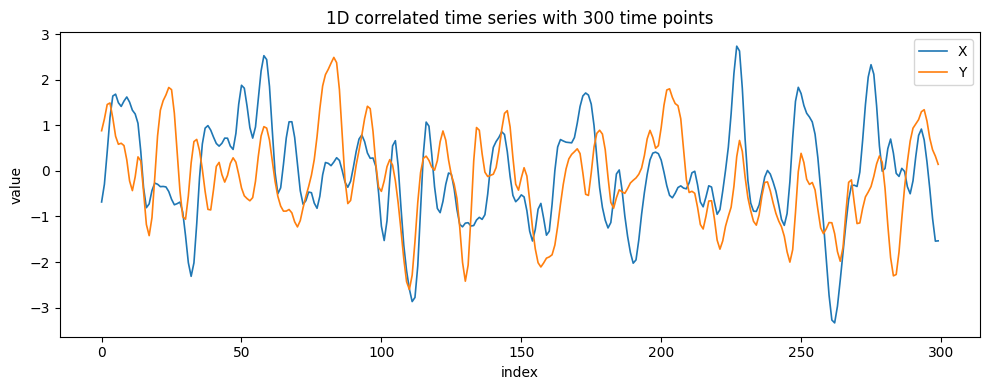

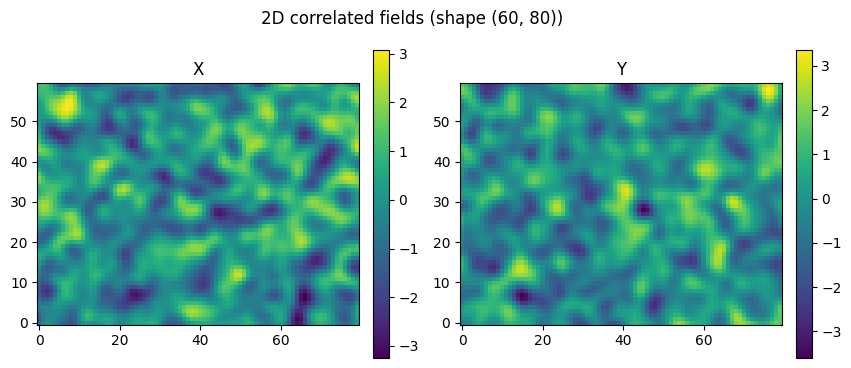

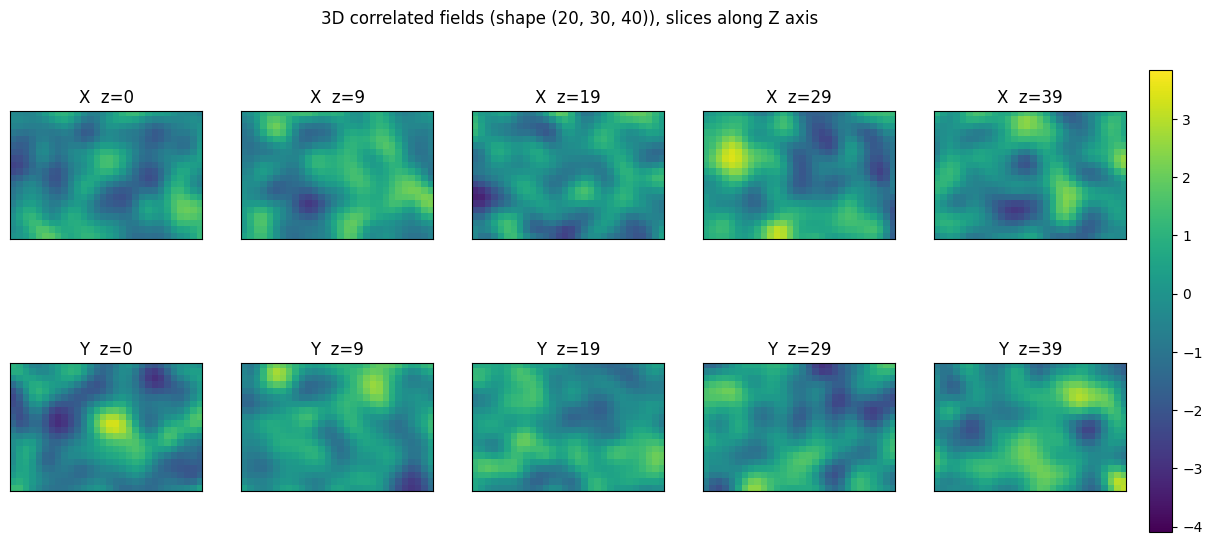

In [47]:
# specify true correlation between the two simulated random fields
rho = 0.3

# simulate 1D time series 
X1, Y1  =  src.gen_corr_field(rho = rho,
    dim=300)

# simulate 2D fields
X2, Y2  =  src.gen_corr_field(rho = rho,
    dim=(60, 80))

# simulate 3D fields
X3, Y3  =  src.gen_corr_field(rho = rho,
    dim=(20,30,40))


# visualize 1D time series
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(X1, label="X", lw=1.2)
ax.plot(Y1, label="Y", lw=1.2)
ax.set_xlabel("index")
ax.set_ylabel("value")
ax.set_title(f"1D correlated time series with {X1.shape[0]} time points")
ax.legend()
fig.tight_layout()
plt.show()

# visualize 2D fields 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, field, title in zip(axes, [X2, Y2], ["X", "Y"]):
    im = ax.imshow(field, origin="lower", cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04) 
fig.suptitle(f"2D correlated fields (shape {X2.shape})")
plt.show()

# visualize 3D fields as a montage of slices along the last axis
n_slices = 5
z_idx = np.linspace(0, X3.shape[2] - 1, n_slices).astype(int)

# shared color scale per field for comparable slices
vmin, vmax = min(X3.min(), Y3.min()), max(X3.max(), Y3.max())

fig, axes = plt.subplots(2, n_slices, figsize=(3 * n_slices, 6))
for row, (field, name) in enumerate(zip([X3, Y3], ["X", "Y"])):
    for col, z in enumerate(z_idx):
        ax = axes[row, col]
        im = ax.imshow(field[:, :, z], origin="lower", cmap="viridis",
                       vmin=vmin, vmax=vmax)
        ax.set_title(f"{name}  z={z}")
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
fig.suptitle(f"3D correlated fields (shape {X3.shape}), slices along Z axis ")
plt.show()




## Correlation between two random fields
Now we compute the correlation between the two random fields, along with its standard error (SE). We can choose different methods to compute the SE. Since typically we are also interested in hypothesis testing under the null of no correlation, the SE under the null is also computed. 

In [37]:
# compute SE, available methods: hac(default), hac_gaussian 
# 1D
rho_est1, se1, se_under_null1, *_ = src.corr(X1, Y1, se_method="hac")
print('----1D----\ncorrelation estimate:', rho_est1, '\nSE:', se1, '\nSE under null:', se_under_null1)

# 2D
rho_est2, se2, se_under_null2, *_ = src.corr(X2, Y2)
print('----2D----\ncorrelation estimate:', rho_est2, '\nSE:', se2, '\nSE under null:', se_under_null2)

# 3D
rho_est3, se3, se_under_null3, *_ = src.corr(X3, Y3)
print('----3D----\ncorrelation estimate:', rho_est3, '\nSE:', se3, '\nSE under null:', se_under_null3)

----1D----
correlation estimate: 0.3554766098539371 
SE: 0.09804672811541908 
SE under null: 0.11978563657805467
----2D----
correlation estimate: 0.3798076447497698 
SE: 0.03791402262202858 
SE under null: 0.05422726007795119
----3D----
correlation estimate: 0.29582315350104094 
SE: 0.027322796207113604 
SE under null: 0.0355320643940739


We can compute the confidence intervals (CI) and p values. By default, 95% CIs are computed and Fisher transformation is used for both CI computaton and p value calculation.

In [38]:
# compute confidence intervals, by default, 95% CI with Fisher transformation 
print('1D 95% CI:', src.confidence_interval(rho_est1, se1))
print('2D 95% CI:', src.confidence_interval(rho_est2, se2))
print('3D 95% CI:', src.confidence_interval(rho_est3, se3))

1D 95% CI: (0.15058134782923313, 0.5310899409680636)
2D 95% CI: (0.30316222047807845, 0.45157064428011306)
3D 95% CI: (0.24138889719327675, 0.34840167734986965)


In [39]:
# compute p value, by default with Fisher transformation 
print('1D p value:', src.pvalue(rho_est1, se_under_null1))
print('2D p value:', src.pvalue(rho_est2, se_under_null2))
print('3D p value:', src.pvalue(rho_est3, se_under_null3))

1D p value: 0.0019154900161038046
2D p value: 1.6653345369377348e-13
3D p value: 0.0
